In [1]:
import re
import json
import glob
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

INPUT = "/kaggle/input/datasets/nocturnalnerd18"
SRC = f"{INPUT}/patch-llava-circuit-dissect"
OUT_DIR = "/kaggle/working"
HELD = ["val", "test"]
N_BOOT = 1000


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{SRC}/circuit_meta.json") as f:
    cm = json.load(f)
STEP_NAMES = cm["step_names"]
entries = []
for path in sorted(glob.glob(f"{SRC}/C_batch_*.pt"), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"] and bool(np.isfinite(e["curve"].numpy()).all())]
print(f"{len(entries)} entries, {len(good)} ok and finite")
CV = np.stack([e["curve"].numpy() for e in good]).astype(np.float64)
dc = np.array([e["delta_clean"] for e in good])
role = np.array([e["stratum"] for e in good])
split = np.array([e["split"] for e in good])
uid = np.array([e["uid"] for e in good])
S = len(STEP_NAMES)
rng = np.random.default_rng(1)

fy_ix = {u: i for u, i in zip(uid[role == "false_yes"], np.flatnonzero(role == "false_yes"))}
ct_ix = {u: i for u, i in zip(uid[role == "true_yes"], np.flatnonzero(role == "true_yes"))}
pairs = sorted(set(fy_ix) & set(ct_ix))
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
held = np.isin(split[a_ix], HELD)
print(f"{len(pairs)} matched units, train {int((~held).sum())}, held-out (val+test) {int(held.sum())}")
assert bool((dc[a_ix] < 0).all()) and bool((dc[b_ix] > 0).all()), "clean runs should be wrong on false_yes and right on true_yes"

200 entries, 200 ok and finite
100 matched units, train 72, held-out (val+test) 28


In [2]:
knock = CV[:, :, 0]
fixed = (knock[a_ix] > 0).astype(float)
hurt = (knock[b_ix] < 0).astype(float)
shift_fy = knock[a_ix] - dc[a_ix, None]
shift_ty = knock[b_ix] - dc[b_ix, None]


def summarize(sel):
    n = len(sel)
    d = rng.integers(0, n, size=(N_BOOT, n))
    out = {}
    for nm, arr in [("fixed", fixed[sel]), ("hurt", hurt[sel]), ("net", fixed[sel] - hurt[sel]), ("shift_fy", shift_fy[sel]), ("shift_ty", shift_ty[sel])]:
        out[nm] = (arr.mean(0), np.percentile(arr[d].mean(1), 2.5, axis=0), np.percentile(arr[d].mean(1), 97.5, axis=0))
    return out


allp = summarize(np.arange(len(pairs)))
tr = summarize(np.flatnonzero(~held))
ho = summarize(np.flatnonzero(held)) if held.sum() >= 5 else None


def f(res, nm, i, d=2):
    m, l, h = res[nm]
    return f"{m[i]:.{d}f} [{l[i]:.{d}f}, {h[i]:.{d}f}]"


def table(names):
    rows = []
    for n in names:
        i = STEP_NAMES.index(n)
        rows.append({
            "step": n, "fixed": f(allp, "fixed", i), "hurt": f(allp, "hurt", i), "net": f(allp, "net", i),
            "net train": f"{tr['net'][0][i]:+.2f}", "net held-out": f"{ho['net'][0][i]:+.2f}" if ho else "n/a",
            "logit shift false_yes": f"{allp['shift_fy'][0][i]:+.2f}", "logit shift true_yes": f"{allp['shift_ty'][0][i]:+.2f}",
        })
    return pd.DataFrame(rows).to_string(index=False)


sets = [n for n in STEP_NAMES if not n.startswith(("single", "loo"))]
singles = [n for n in STEP_NAMES if n.startswith("single")]
loos = [n for n in STEP_NAMES if n.startswith("loo")]
print(f"--- sets: knockout flips over {len(pairs)} matched units; fixed = false_yes answers moved to No, hurt = true_yes answers moved to No ---")
print(table(sets))
print("--- each cell alone ---")
print(table(singles))
print("--- cells left out of a set (same columns, for the reduced set) ---")
print(table(loos))
print("net is fixed minus hurt; the logit shift is the mean change of the correct-answer margin, positive moves towards the right answer")
print("knockout here swaps in the activations of the noisy-image run, so this measures what the set does to the answer and is not a deployable edit")

--- sets: knockout flips over 100 matched units; fixed = false_yes answers moved to No, hurt = true_yes answers moved to No ---
step             fixed              hurt                net net train net held-out logit shift false_yes logit shift true_yes
   P 0.02 [0.00, 0.05] 0.00 [0.00, 0.00]  0.02 [0.00, 0.05]     +0.03        +0.00                 +1.46                -1.08
   B 0.00 [0.00, 0.00] 0.00 [0.00, 0.00]  0.00 [0.00, 0.00]     +0.00        +0.00                 -1.83                +1.10
  PA 0.40 [0.30, 0.49] 0.32 [0.23, 0.41] 0.08 [-0.06, 0.22]     +0.12        -0.04                 +2.69                -2.48
--- each cell alone ---
                  step             fixed              hurt                 net net train net held-out logit shift false_yes logit shift true_yes
        single:L11 H26 0.00 [0.00, 0.00] 0.00 [0.00, 0.00]   0.00 [0.00, 0.00]     +0.00        +0.00                 +0.68                -0.40
        single:L16 MLP 0.00 [0.00, 0.00] 0.00 [0.00, 0

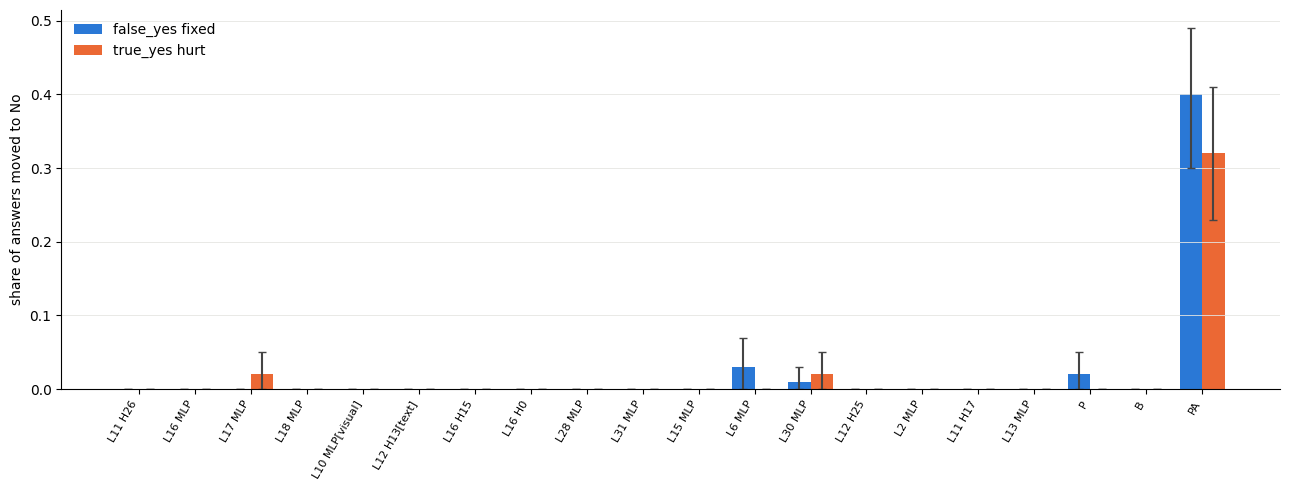

In [3]:
order = [n for n in STEP_NAMES if n.startswith("single")] + ["P", "B", "PA"]
order = [n for n in order if n in STEP_NAMES]
idx = [STEP_NAMES.index(n) for n in order]
BLUE, ORANGE = "#2a78d6", "#eb6834"
fig, ax = plt.subplots(figsize=(13, 5))
xs = np.arange(len(order))
ax.bar(xs - 0.2, allp["fixed"][0][idx], width=0.4, color=BLUE, label="false_yes fixed")
ax.bar(xs + 0.2, allp["hurt"][0][idx], width=0.4, color=ORANGE, label="true_yes hurt")
ax.errorbar(xs - 0.2, allp["fixed"][0][idx], yerr=[allp["fixed"][0][idx] - allp["fixed"][1][idx], allp["fixed"][2][idx] - allp["fixed"][0][idx]], fmt="none", ecolor="#444444", capsize=3)
ax.errorbar(xs + 0.2, allp["hurt"][0][idx], yerr=[allp["hurt"][0][idx] - allp["hurt"][1][idx], allp["hurt"][2][idx] - allp["hurt"][0][idx]], fmt="none", ecolor="#444444", capsize=3)
ax.set_xticks(xs)
ax.set_xticklabels([n.replace("single:", "") for n in order], rotation=60, ha="right", fontsize=8)
ax.set_ylabel("share of answers moved to No")
ax.legend(frameon=False)
ax.grid(color="#e5e5e2", lw=0.6, axis="y")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/circuit_flips.png", dpi=150)
plt.show()

with open(f"{OUT_DIR}/circuit_flips.json", "w") as f:
    json.dump({
        "step_names": STEP_NAMES, "n_pairs": len(pairs), "fixed": allp["fixed"][0].tolist(), "hurt": allp["hurt"][0].tolist(), "net": allp["net"][0].tolist(),
        "net_train": tr["net"][0].tolist(), "net_held": ho["net"][0].tolist() if ho else None,
    }, f)